In [9]:
import os, io, json, math, numpy as np, matplotlib.pyplot as plt
from urllib.request import urlopen, Request
from pynwb import NWBHDF5IO

import ephys_extractor as ex   # your uploaded file
import ephys_features as ft    # your uploaded file


In [16]:
import numpy as np

def series_values_with_conversion(series):
    """
    Apply series.conversion/offset once, and return the values in the units
    declared by series.unit (which might be V, mV, uV ... or A, nA, pA ...).
    """
    data = np.asarray(series.data[:], dtype=float)
    conv = float(getattr(series, "conversion", 1.0))
    offs = float(getattr(series, "offset", 0.0))
    return data * conv + offs, (getattr(series, "unit", "") or "").lower()

def as_mV(values, unit):
    # Convert values (currently in `unit`) to millivolts
    u = (unit or "").lower()
    if u in ("v", "volt", "volts"):         return values * 1e3
    if u in ("mv", "millivolt", "millivolts"): return values
    if u in ("uv", "microvolt", "microvolts"): return values * 1e-3
    if u in ("nv", "nanovolt", "nanovolts"):   return values * 1e-6
    # unknown → assume volts
    return values * 1e3

def as_pA(values, unit):
    # Convert values (currently in `unit`) to picoamps
    u = (unit or "").lower()
    if u in ("a", "ampere", "amperes", "amp", "amps"): return values * 1e12
    if u in ("na", "nanoamp", "nanoamps", "nanoampere", "nanoamperes"): return values * 1e3
    if u in ("pa", "picoamp", "picoamps", "picoampere", "picoamperes"): return values
    if u in ("ua", "microamp", "microamps", "microampere", "microamperes"): return values * 1e6
    # unknown → assume amperes
    return values * 1e12

def build_time(resp):
    if resp.timestamps is not None:
        return np.asarray(resp.timestamps[:], float)
    rate = float(resp.rate)
    return np.arange(resp.data.shape[0], dtype=float) / rate

def extract_v_i_in_mV_pA(resp, stim):
    # Voltage
    v_vals, v_unit = series_values_with_conversion(resp)
    v_mV = as_mV(v_vals, v_unit)
    # Current
    if stim is not None:
        i_vals, i_unit = series_values_with_conversion(stim)
        i_pA = as_pA(i_vals, i_unit)
    else:
        i_pA = np.zeros_like(v_mV)
    return v_mV, i_pA


In [17]:
def summarize_sweep(resp, stim):
    t = build_time(resp)
    v = to_mV(series_to_SI(resp))
    i = to_pA(series_to_SI(stim)) if stim is not None else np.zeros_like(v)

    # window + baseline (pre-stim −200 ms to 0)
    t_start, t_end = detect_step_window(i, t)
    baseline_mask = (t >= max(t[0], t_start - 0.2)) & (t < t_start)
    Vrest = float(np.nanmedian(v[baseline_mask])) if baseline_mask.any() else float(np.nanmedian(v))

    # quick depolarization magnitude
    stim_mask = (t >= t_start) & (t <= t_end)
    depol = float(np.nanmax(v[stim_mask]) - np.nanmedian(v[baseline_mask])) if stim_mask.any() else 0.0

    # run extractor to count spikes (fast)
    swe = ex.EphysSweepFeatureExtractor(t=t, v=v, i=i, start=float(t_start), end=float(t_end))
    swe.process_spikes()
    n_spikes = len(getattr(swe, "_spikes_df", []))
    return dict(t=t, v=v, i=i, Vrest=Vrest, depol=depol, t_start=float(t_start), t_end=float(t_end), n_spikes=n_spikes, swe=swe)

def choose_best_sweep(nwb):
    best = None
    best_key = None
    for key, resp, stim in iter_cc_sweeps(nwb):
        s = summarize_sweep(resp, stim)
        s["key"] = key
        if best is None:
            best, best_key = s, key
        else:
            # prefer spiking sweeps with more spikes; else larger depolarization
            if (s["n_spikes"] > max(best["n_spikes"], 0)) or (s["n_spikes"] == best["n_spikes"] and s["depol"] > best["depol"]):
                best, best_key = s, key
    return best


In [18]:
def describe_cell_from_asset(nwb_path):
    with NWBHDF5IO(nwb_path, "r", load_namespaces=True) as io:
        nwb = io.read()
        s = choose_best_sweep(nwb)

    swe = s["swe"]  # already processed
    sf = getattr(swe, "_sweep_features", {})
    try: sag, sag_ratio = swe.estimate_sag()
    except: sag, sag_ratio = (math.nan, math.nan)
    try: tau_s = swe.estimate_time_constant()
    except: tau_s = math.nan

    desc = {
        "sweep_key": s["key"],
        "resting_V_mV": float(s["Vrest"]),
        "mean_rate_Hz": float(sf.get("avg_rate", np.nan)),
        "ISI_mean_s": float(sf.get("mean_isi", np.nan)),
        "ISI_CV": float(sf.get("cv", np.nan)),
        "adaptation_index": float(sf.get("adapt", np.nan)),
        "amp_adapt_ratio": float(sf.get("AP_amp_adapt", np.nan)),
        "amp_adapt_avg": float(sf.get("AP_amp_adapt_average", np.nan)),
        "AP_amp_Fano": float(sf.get("AP_fano_factor", np.nan)),
        "sag_fraction": float(sag),
        "sag_ratio": float(sag_ratio),
        "tau_s": float(tau_s),
        "stim_start_s": s["t_start"],
        "stim_end_s": s["t_end"],
        "n_spikes": int(s["n_spikes"]),
        # sanity ranges for quick unit QA
        "Vm_range_mV": [float(np.nanmin(s["v"])), float(np.nanmax(s["v"]))],
        "I_range_pA":  [float(np.nanmin(s["i"])), float(np.nanmax(s["i"]))],
    }
    return desc, s


In [19]:
# download once, then analyze
nwb_path = "DandiSetData/000008/sub-mouse-AAYYT/sub-mouse-AAYYT_ses-20180420-sample-3_slice-20180420-slice-3_cell-20180420-sample-3_icephys.nwb"
info, s = describe_cell_from_asset(nwb_path)
info


/home/peter/.local/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.3.0 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/home/peter/.local/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.2.5 because version 2.7.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/home/peter/.local/lib/python3.10/site-packages/pynwb/icephys.py:226: UserWarning: Stimulus description 'NA' for IZeroClampSeries 'CurrentClampSeries010' is ignored and will be set to 'N/A' as per NWB 2.3.0.
  warnings.warn(


A DOWNWARD PEAK WAS OBSERVED GOING TO LESS THAN 200 MV!!!
A DOWNWARD PEAK WAS OBSERVED GOING TO LESS THAN 200 MV!!!


{'sweep_key': 'CurrentClampSeries076',
 'resting_V_mV': -66117.73371696472,
 'mean_rate_Hz': 808.3872258150543,
 'ISI_mean_s': 0.0012355463917525773,
 'ISI_CV': 0.5751382499333885,
 'adaptation_index': -0.0026042636661838263,
 'amp_adapt_ratio': 0.14090447267959696,
 'amp_adapt_avg': 2.846824721090788,
 'AP_amp_Fano': 75969.2268661884,
 'sag_fraction': 1719.3337905870148,
 'sag_ratio': -0.000581959107990527,
 'tau_s': nan,
 'stim_start_s': 0.1,
 'stim_end_s': 0.69996,
 'n_spikes': 486,
 'Vm_range_mV': [-66362.51509189606, 68156.34667873383],
 'I_range_pA': [-200000000000000.0, 0.0]}

/home/peter/.local/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.3.0 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/home/peter/.local/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.2.5 because version 2.7.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/home/peter/.local/lib/python3.10/site-packages/pynwb/icephys.py:226: UserWarning: Stimulus description 'NA' for IZeroClampSeries 'CurrentClampSeries010' is ignored and will be set to 'N/A' as per NWB 2.3.0.
  warnings.warn(


Selected sweep: CurrentClampSeries076
Baseline Vm (mV): -66117.73
Spike count: 486
Vm range (mV): -66362.52 .. 68156.35
I range (pA):  -200000000000000.0 .. 0.0


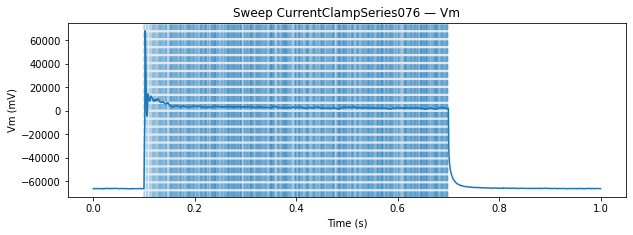

ValueError: x and y must have same first dimension, but have shapes (25000,) and (22500,)

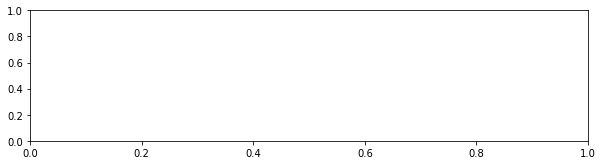

In [20]:
import numpy as np, math
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO
import ephys_extractor as ex

# --- set your file path here (download step you already ran) ---
nwb_path = nwb_path  # or: "/full/path/to/sub-mouse-AAYYT_..._icephys.nwb"

# ---------- helpers (scaling-aware) ----------
def series_to_SI(series):
    data = np.asarray(series.data[:], dtype=float)
    conv = getattr(series, "conversion", 1.0)
    offs = getattr(series, "offset", 0.0)
    return data * conv + offs   # SI units (V or A)

def to_mV(v_volts): return v_volts * 1e3
def to_pA(i_amps):  return i_amps  * 1e12

def build_time(resp):
    if resp.timestamps is not None:
        t = np.asarray(resp.timestamps[:], float)
    else:
        rate = float(resp.rate)
        t = np.arange(resp.data.shape[0], dtype=float) / rate
    return t

def detect_step_window(i_pA, t, frac=0.02, floor=5.0):
    thr = max(floor, frac * (np.nanmax(np.abs(i_pA)) if i_pA.size else 0.0))
    on = np.where(np.abs(i_pA) > thr)[0]
    if on.size >= 5:
        return float(t[on[0]]), float(t[on[-1]])
    # fallback: centered 0.5 s window
    if len(t) > 10:
        mid = int(len(t)*0.5)
        rate = 1.0/np.median(np.diff(t))
        return float(t[max(0, mid-int(0.25*rate))]), float(t[min(len(t)-1, mid+int(0.25*rate))])
    return float(t[0]), float(t[-1])

def iter_cc_sweeps(nwb):
    st = getattr(nwb, "icephys_sweep_table", None)
    if st is not None and len(st) > 0:
        df = st.to_dataframe()
        for idx, row in df.iterrows():
            yield idx, row["response"], row.get("stimulus")
    else:
        for name, obj in nwb.acquisition.items():
            if obj.neurodata_type == "CurrentClampSeries":
                resp = obj
                stim = None
                if hasattr(nwb, "stimulus"):
                    for s in nwb.stimulus.values():
                        if s.neurodata_type == "CurrentClampStimulusSeries":
                            stim = s; break
                yield name, resp, stim

def summarize_sweep(resp, stim):
    t = build_time(resp)
    v = to_mV(series_to_SI(resp))
    i = to_pA(series_to_SI(stim)) if stim is not None else np.zeros_like(v)
    t0, t1 = detect_step_window(i, t)
    pre = (t >= max(t[0], t0-0.2)) & (t < t0)
    Vrest = float(np.nanmedian(v[pre])) if pre.any() else float(np.nanmedian(v))
    depol = float((np.nanmax(v[(t>=t0)&(t<=t1)]) if (t<=t1).any() else np.nan) - Vrest)
    swe = ex.EphysSweepFeatureExtractor(t=t, v=v, i=i, start=t0, end=t1)
    swe.process_spikes()
    nsp = len(getattr(swe, "_spikes_df", []))
    return dict(key=None, t=t, v=v, i=i, t0=t0, t1=t1, Vrest=Vrest, depol=depol, nsp=nsp, swe=swe)

def choose_best_sweep(nwb):
    best = None
    for key, resp, stim in iter_cc_sweeps(nwb):
        s = summarize_sweep(resp, stim)
        s["key"] = key
        if best is None:
            best = s
        else:
            if (s["nsp"] > best["nsp"]) or (s["nsp"] == best["nsp"] and s["depol"] > best["depol"]):
                best = s
    return best

# ---------- load & plot ----------
with NWBHDF5IO(nwb_path, "r", load_namespaces=True) as io:
    nwb = io.read()
    s = choose_best_sweep(nwb)

print(f"Selected sweep: {s['key']}")
print(f"Baseline Vm (mV): {s['Vrest']:.2f}")
print(f"Spike count: {s['nsp']}")
print(f"Vm range (mV): {np.nanmin(s['v']):.2f} .. {np.nanmax(s['v']):.2f}")
print(f"I range (pA):  {np.nanmin(s['i']):.1f} .. {np.nanmax(s['i']):.1f}")

# Voltage
plt.figure(figsize=(10,3.2))
plt.plot(s["t"], s["v"])
plt.axvspan(s["t0"], s["t1"], alpha=0.15)
plt.xlabel("Time (s)"); plt.ylabel("Vm (mV)"); plt.title(f"Sweep {s['key']} — Vm")
spk = getattr(s["swe"], "_spikes_df", None)
if spk is not None and len(spk):
    for ts in spk["threshold_t"]:
        plt.axvline(ts, linestyle="--", alpha=0.3)
plt.show()

# Current
plt.figure(figsize=(10,2.4))
plt.plot(s["t"], s["i"])
plt.axvspan(s["t0"], s["t1"], alpha=0.15)
plt.xlabel("Time (s)"); plt.ylabel("I (pA)"); plt.title("Stimulus")
plt.show()
